In [1]:
import pandas as pd
import yaml 
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from decimal import Decimal
from datetime import datetime
from dateutil import parser
import networkx as nx

data exploration

In [2]:
df_users = pd.read_csv('users.csv')
df_users = pd.DataFrame(df_users)

df_books = yaml.safe_load(open('books.yaml'))
df_books = pd.DataFrame(df_books)

df_orders = pq.read_table('orders.parquet').to_pandas()
df_orders = pq.ParquetDataset('orders.parquet').read().to_pandas()

In [3]:
df_users.head()
len(df_users)
df_users.info()

df_users.duplicated().sum()


<class 'pandas.DataFrame'>
RangeIndex: 3107 entries, 0 to 3106
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   id       3107 non-null   int64
 1   name     3107 non-null   str  
 2   address  2994 non-null   str  
 3   phone    3107 non-null   str  
 4   email    3107 non-null   str  
dtypes: int64(1), str(4)
memory usage: 427.1 KB


np.int64(0)

In [4]:
print(type(df_books))
df_books.info()
print(df_books.isna().sum(), "\n")
print(df_books.duplicated().sum())

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
RangeIndex: 742 entries, 0 to 741
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   :id         742 non-null    int64 
 1   :title      742 non-null    str   
 2   :author     742 non-null    str   
 3   :genre      742 non-null    str   
 4   :publisher  742 non-null    str   
 5   :year       741 non-null    object
dtypes: int64(1), object(1), str(4)
memory usage: 83.3+ KB
:id           0
:title        0
:author       0
:genre        0
:publisher    0
:year         1
dtype: int64 

0


In [5]:
len(df_orders)
df_orders.info()
print(df_orders.isna().sum(), "\n")
print(df_orders.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9280 entries, 0 to 9279
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          9280 non-null   int64
 1   user_id     9280 non-null   int64
 2   book_id     9280 non-null   int64
 3   quantity    9280 non-null   int32
 4   unit_price  9280 non-null   str  
 5   timestamp   9280 non-null   str  
 6   shipping    7032 non-null   str  
dtypes: int32(1), int64(3), str(3)
memory usage: 839.8 KB
id               0
user_id          0
book_id          0
quantity         0
unit_price       0
timestamp        0
shipping      2248
dtype: int64 

0


In [6]:
print(df_users.isna().sum(), "\n")
print(df_users.duplicated().sum())



id           0
name         0
address    113
phone        0
email        0
dtype: int64 

0


data cleaning

In [7]:
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].unique(), "\n")
print(df_orders['timestamp'].head(20))

0      47.99 $
1    USD 62.75
2      USD16.0
3      31.50 $
4       € 33.5
5       64.00€
6    USD 34.25
7      EUR73.5
8      USD 35.
9    USD 65.99
Name: unit_price, dtype: str 

<ArrowStringArray>
[  '47.99 $', 'USD 62.75',   'USD16.0',   '31.50 $',    '€ 33.5',    '64.00€',
 'USD 34.25',   'EUR73.5',   'USD 35.', 'USD 65.99',
 ...
   'USD24.0',    '14.0 $',    '$25.50',  'EUR40.00',       '€47',   '€ 64.99',
    '23.50$',     'USD65',     '€ 35.',  '47.75EUR']
Length: 5712, dtype: str 

0          21:36, 18-FEB-2025
1        18-DEC-2025;21:42:51
2              04/02/26,17:29
3      11:24,  6-October-2025
4     2026-04-18T11:31:01.628
5      01:17:23 P.M.;04/23/26
6            02:27,2026-03-01
7            2025-07-15,06:45
8      05:53:21 am;2026-01-27
9              14:05;12/02/25
10     11-December-2025,20:23
11            10/30/25, 09:37
12             21:19,09/22/25
13    2026-07-26T07:50:03.701
14         13:51,17-June-2025
15          2026-08-07, 03:14
16    2026-03-13T08:40:1

In [8]:
print(df_books[':year'].unique()[:20], "\n")

[2011 1976 1980 1985 1995 2018 1986 2009 1993 2026 2001 2022 2021 1987
 1997 2023 2020 1990 1999 1979] 



In [9]:
#function to change currency to usd and clean signs such as $ or eur

def convert_to_usd(unit_price):
    clean_price = unit_price.replace("$", "").replace("EUR", "").replace("€", "").replace("USD", "").replace("¢", ".").strip()
   
    if "€" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("€", ".").replace("¢", "")
        return Decimal(clean_price) * Decimal("1.2")

    if "$" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("$", ".").replace("¢", "")
        return Decimal(clean_price)
    value = Decimal(clean_price)
    if "EUR" in unit_price or "€" in unit_price:
        currency = value * Decimal("1.2")
    elif "$" in unit_price or "USD" in unit_price:
        currency = value
    else:
        raise ValueError("Unsupported currency")
    
    return currency

In [10]:
print(convert_to_usd("EUR72.75"))  # test

87.300


In [11]:
df_orders['unit_price'] = df_orders['unit_price'].apply(convert_to_usd)
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].isna().sum())

0     47.99
1     62.75
2      16.0
3     31.50
4     40.20
5    76.800
6     34.25
7     88.20
8        35
9     65.99
Name: unit_price, dtype: object 

0


In [12]:
#paid price = quentity * unit_price
df_orders['paid_price'] = df_orders['quantity'] * df_orders['unit_price']
print(df_orders[['quantity', 'unit_price', 'paid_price']].head(20))


    quantity unit_price paid_price
0          1      47.99      47.99
1          1      62.75      62.75
2          1       16.0       16.0
3          1      31.50      31.50
4          3      40.20     120.60
5          1     76.800     76.800
6          3      34.25     102.75
7          1      88.20      88.20
8          1         35         35
9          1      65.99      65.99
10         1     86.700     86.700
11         1     61.500     61.500
12         3      49.99     149.97
13         1       46.5       46.5
14         1     72.600     72.600
15         2       36.5       73.0
16         1      48.75      48.75
17         1     18.900     18.900
18         1       37.0       37.0
19         1     40.500     40.500


In [13]:
def timestamp_parser(value):
    try:
        value = str(value).strip()
        value = value.replace(",", " ").replace(";"," ")
        value = value.replace("A.M.", "AM").replace("P.M.", "PM")
        return parser.parse(value)
    except(ValueError, TypeError):
        return pd.NaT
    

In [14]:
df_orders['parsed_timestamp'] = df_orders['timestamp'].apply(timestamp_parser)
print(df_orders['parsed_timestamp'].isna().sum())

0


In [15]:
print(df_orders.columns.tolist())

['id', 'user_id', 'book_id', 'quantity', 'unit_price', 'timestamp', 'shipping', 'paid_price', 'parsed_timestamp']


In [16]:
df_orders['date'] = pd.to_datetime(df_orders['parsed_timestamp']).dt.date
print(df_orders[['parsed_timestamp', 'date']].head(5))

         parsed_timestamp        date
0 2025-02-18 21:36:00.000  2025-02-18
1 2025-12-18 21:42:51.000  2025-12-18
2 2026-04-02 17:29:00.000  2026-04-02
3 2025-10-06 11:24:00.000  2025-10-06
4 2026-04-18 11:31:01.628  2026-04-18


In [17]:
daily_revenue = df_orders.groupby('date')['paid_price'].sum()
top5rev = daily_revenue.sort_values(ascending = False).head(5)
print(top5rev)

date
2025-10-09      3716.190
2025-09-21    3162.80200
2025-09-30     2859.6930
2025-09-01     2851.7850
2025-10-25    2803.69800
Name: paid_price, dtype: object


In [18]:
def same_user(user1, user2):
    columns = ['name', 'address', 'phone', 'email']
    matches = 0

    for col in columns:
        if pd.notna(user1[col]) and pd.notna(user2[col]):
            if user1[col] == user2[col]:
                matches += 1

    return matches >= 3

In [19]:
G = nx.Graph()
for user_id in df_users['id']:
    G.add_node(user_id)
for i in range(len(df_users)):
    for j in range(i + 1, len(df_users)):
        user1 = df_users.iloc[i]
        user2 = df_users.iloc[j]

        if same_user(user1, user2):
            G.add_edge(user1['id'], user2['id'])

In [20]:
groups = list(nx.connected_components(G))
unique_users_count = len(groups)
print("Total user ID:", len(df_users))
print("Unique users:", unique_users_count)

Total user ID: 3107
Unique users: 2955


In [21]:
user_mapping = {}
for group in groups:
    real_id = min(group)
    for user_id in group:
        user_mapping[user_id] = real_id

df_users['real_user_id'] = df_users['id'].map(user_mapping)
print(df_users[['id', 'real_user_id']].head(10))

      id  real_user_id
0  53844         53449
1  54948         54948
2  52201         52201
3  54733         54733
4  52961         52961
5  54573         54573
6  53002         53002
7  54520         54520
8  52205         52205
9  52349         52349


In [22]:
multiple_ids = [group for group in groups if len(group) > 1]

print("Users with multiple IDs:", len(multiple_ids))
print("Examples:", multiple_ids[:15])

Users with multiple IDs: 139
Examples: [{np.int64(53449), 53844}, {52465, np.int64(54891)}, {np.int64(54296), 54649}, {54848, np.int64(52678), np.int64(52671)}, {np.int64(55034), 52194, np.int64(52751)}, {53593, np.int64(52181), np.int64(53375)}, {np.int64(54811), 54155}, {np.int64(54913), np.int64(52167), 52495}, {np.int64(53011), 53124}, {np.int64(52873), 54319}, {54553, np.int64(52404)}, {np.int64(54896), 53451}, {np.int64(53835), 54828}, {np.int64(54105), 54444}, {54028, np.int64(54382)}]


In [23]:
print("Total groups:", len(groups))
print("Multiple ID groups:", len(multiple_ids))

for group in multiple_ids[:5]:
    display(df_users[df_users['id'].isin(group)])

Total groups: 2955
Multiple ID groups: 139


,id,name,address,phone,email,real_user_id
0,53844,Cristopher Kassulke Jr.,"Suite 710 62794 Audry Hollow, Beattyport, NE 7...",700.721.1941,chanelle@jaskolski-stroman.test,53449
67,53449,Krista Stamm,"Suite 710 62794 Audry Hollow, Beattyport, NE 7...",700.721.1941,chanelle@jaskolski-stroman.test,53449


,id,name,address,phone,email,real_user_id
10,52465,Sherlene Hand,"115 Burl Mill, Port Todfort, RI 47242-6652",784 407 4553,dale_keebler@king-walker.test,52465
2902,54891,Sherlene Hand,"115 Burl Mill, Port Todfort, RI 47242-6652",784 407 4553,martin@reynolds.example,52465


,id,name,address,phone,email,real_user_id
13,54649,Jacelyn Mills VM,"Suite 504 647 Renner Orchard, Port Allenburgh,...",927.141.8724,norman_grant@hand.test,54296
2946,54296,Jacelyn Mills VM,"2450 Jim Heights, Port Aron, MA 10050",927.141.8724,norman_grant@hand.test,54296


,id,name,address,phone,email,real_user_id
20,54848,Joey Stoltenberg DVM,"Apt. 528 28930 George Village, East Santo, CT ...",142-732-2845,graham_cummings@brekke-volkman.test,52671
1664,52678,Alba Stanton V,"Apt. 528 28930 George Village, East Santo, CT ...",142-732-2845,graham_cummings@brekke-volkman.test,52671
2568,52671,Alba Stanton V,"5532 Terrence Via, Rosarioshire, WA 37570-7661",142-732-2845,graham_cummings@brekke-volkman.test,52671


,id,name,address,phone,email,real_user_id
21,52194,Merle Konopelski,"572 Yahaira Ways, West Myrtice, NY 58443-4012",547-835-7908,carroll@boehm-lockman.example,52194
1565,52751,Merle Konopelski,"572 Yahaira Ways, West Myrtice, NY 58443-4012",505-561-6477,carroll@boehm-lockman.example,52194
2455,55034,Pres. Connie Torp,"572 Yahaira Ways, West Myrtice, NY 58443-4012",505-561-6477,carroll@boehm-lockman.example,52194


In [24]:
print("Largest group:", max(len(group) for group in groups))

Largest group: 3


In [25]:
missing_address = df_users[df_users['address'].isna()]

print("Missing addresses:", len(missing_address))
print("Unique real users:", missing_address['real_user_id'].nunique())

Missing addresses: 113
Unique real users: 113


In [26]:
print(df_books.columns.tolist())
print(df_books[':author'].head(10).to_string())

[':id', ':title', ':author', ':genre', ':publisher', ':year']
0                                  Rep. Lavonia Fisher
1                    Angelina Rowe, Suzie Romaguera DC
2    Fr. Mahalia Morissette, Milan Moen, Jude Runol...
3                                      Sheri Krajcik I
4    Breana Hagenes IV, Amb. Garnett Krajcik, Jc Fahey
5                                         Jimmy Hessel
6                                        Elliot Gibson
7    Gema Breitenberg DC, Cortney Parker, Denisha F...
8                  Julianne Doyle, Pres. Stuart Zulauf
9                                           Isaac Hand


In [27]:
def split_names(authors):
    names = authors.split(",")
    names = [name.strip() for name in names]
    return frozenset(names)

In [28]:
df_books['authors'] = df_books[':author'].apply(split_names)
unique_authors = df_books['authors'].nunique()
print("Unique authors:", unique_authors)

Unique authors: 307


In [29]:
print(df_books[[':author', 'authors']].head(5))

                                             :author  \
0                                Rep. Lavonia Fisher   
1                  Angelina Rowe, Suzie Romaguera DC   
2  Fr. Mahalia Morissette, Milan Moen, Jude Runol...   
3                                    Sheri Krajcik I   
4  Breana Hagenes IV, Amb. Garnett Krajcik, Jc Fahey   

                                             authors  
0                   frozenset({Rep. Lavonia Fisher})  
1     frozenset({Suzie Romaguera DC, Angelina Rowe})  
2  frozenset({Jude Runolfsdottir PhD, Fr. Mahalia...  
3                       frozenset({Sheri Krajcik I})  
4  frozenset({Jc Fahey, Breana Hagenes IV, Amb. G...  


In [30]:
df_merged = df_orders.merge(df_books, left_on='book_id', right_on=':id')
author_sales = df_merged.groupby('authors')['quantity'].sum()
author_sales = author_sales.sort_values(ascending=False)

print(author_sales.head(5))

authors
frozenset({Loreta Metz})                            155
frozenset({Cortney Parker, Msgr. Aaron D'Amore})    140
frozenset({Ivey Kerluke II})                        134
frozenset({Dr. Delores Batz})                       133
frozenset({Ashley Huel Sr.})                        120
Name: quantity, dtype: int32


In [31]:
df_orders['real_user_id'] = df_orders['user_id'].map(user_mapping)

print(df_orders[['user_id', 'real_user_id', 'paid_price']].head(10))
print("Missing users:", df_orders['real_user_id'].isna().sum())

buyer_spending = df_orders.groupby('real_user_id')['paid_price'].sum()
buyer_spending = buyer_spending.sort_values(ascending=False)

print(buyer_spending.head(5))
best_buyer = buyer_spending.index[0]

buyer_ids = df_users[df_users['real_user_id'] == best_buyer]['id'].tolist()

print("Best buyer IDs:", buyer_ids)
print("Total spending:", buyer_spending.iloc[0])

   user_id  real_user_id paid_price
0    52830         52830      47.99
1    55117         55117      62.75
2    54993         54993       16.0
3    54915         54915      31.50
4    54759         54759     120.60
5    55028         55028     76.800
6    54228         54228     102.75
7    54266         54266      88.20
8    52184         52184         35
9    54846         52881      65.99
Missing users: 0
real_user_id
54663      1294.640
52565      1216.426
52465    1122.30400
53511      1086.250
52964      1077.050
Name: paid_price, dtype: object
Best buyer IDs: [54663]
Total spending: 1294.640


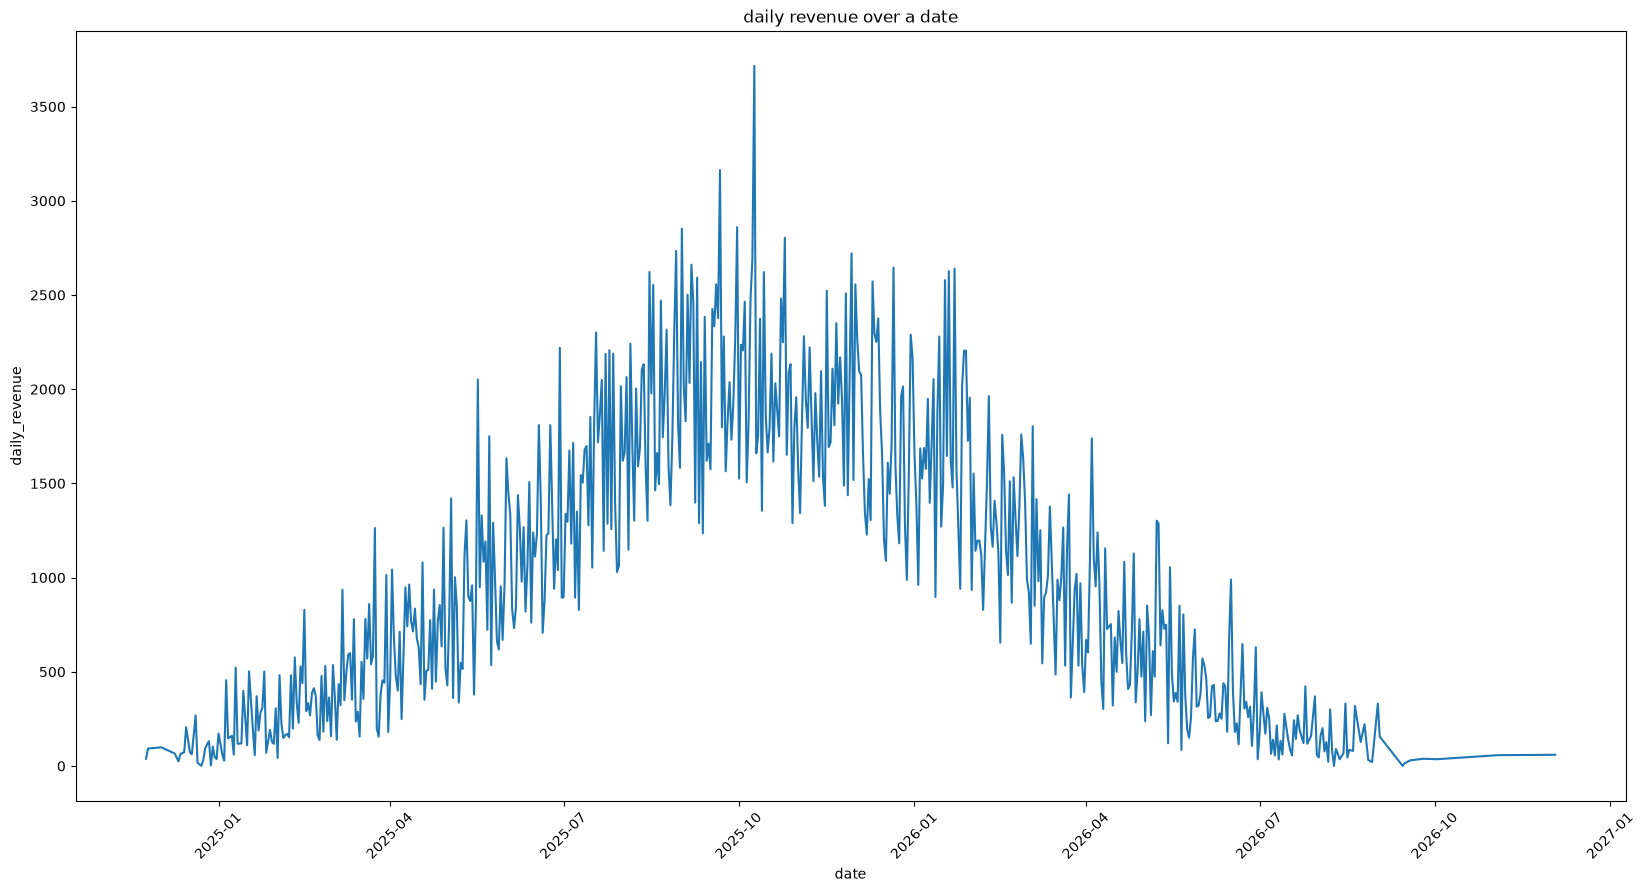

In [32]:
daily_revenue = daily_revenue.sort_index()
plt.figure(figsize=(20, 10))
plt.plot(daily_revenue.index, daily_revenue.astype(float))
plt.xlabel('date')
plt.xticks(rotation=45)
plt.ylabel('daily_revenue')
plt.title('daily revenue over a date')
plt.show()